# PCA — 何次元まで落とせるか

**出典**　機械学習 4 分野の教科書 — 第 10 章 3-B 次元削減と異常検知 ／ 07 実装：圧縮して、見て、異常を見つける

**このノートのパス**　`ml-code/10_dimreduction_anomaly/01_pca.ipynb`

**このノートで確かめること**
**累積寄与率**で必要な次元数を決め、そこまで落としてから k-means を掛ける。
**PCA を Pipeline に入れる**ことでリークを防ぐ書き方も確かめる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn numpy matplotlib` |
| 実行時間の目安 | 約 15 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

(1797, 64)
分散の 95% を保つのに必要な次元数: 40 / 64


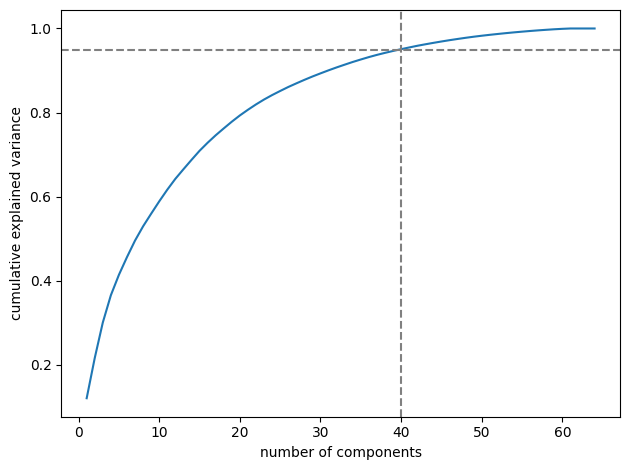

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline

RS = 42
X, y = load_digits(return_X_y=True)     # 8x8 の手書き数字 = 64 次元, 1797 枚
print(X.shape)                          # (1797, 64)

scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)

# --- 何次元まで落とせるか：累積寄与率を見る ---
pca_full = PCA().fit(Xs)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"分散の 95% を保つのに必要な次元数: {n95} / {X.shape[1]}")

plt.plot(range(1, len(cum) + 1), cum, "-")
plt.axhline(0.95, ls="--", color="gray"); plt.axvline(n95, ls="--", color="gray")
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance")
plt.tight_layout(); plt.show()

In [4]:
# --- n95 次元に落としてから k-means（生の 64 次元より安定する） ---
pipe = make_pipeline(StandardScaler(), PCA(n_components=n95, random_state=RS),
                     KMeans(n_clusters=10, n_init=10, random_state=RS))
labels = pipe.fit_predict(X)

from sklearn.metrics import adjusted_rand_score, silhouette_score
print("PCA あり  ARI:", round(adjusted_rand_score(y, labels), 4))

raw = make_pipeline(StandardScaler(),
                    KMeans(n_clusters=10, n_init=10, random_state=RS)).fit_predict(X)
print("PCA なし  ARI:", round(adjusted_rand_score(y, raw), 4))
print("\n※ ARI は正解ラベル y との一致度。ここでは比較のためだけに使っている")

  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


PCA あり  ARI: 0.5694
PCA なし  ARI: 0.5344

※ ARI は正解ラベル y との一致度。ここでは比較のためだけに使っている


### 圧縮して戻すと、何が失われたかが見える

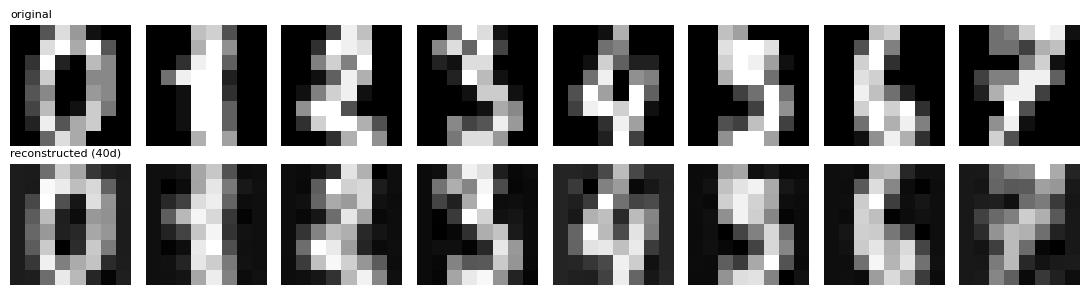

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
p = PCA(n_components=n95, random_state=RS).fit(Xs)
recon = scaler.inverse_transform(p.inverse_transform(p.transform(Xs)))
for i in range(8):
    axes[0, i].imshow(X[i].reshape(8, 8), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(recon[i].reshape(8, 8), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left")
axes[1, 0].set_title(f"reconstructed ({n95}d)", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 読み取りどころ

- **64 次元のうち、分散の 95% は 40 次元程度で説明できる。**残りの次元はほとんどノイズで、距離計算を薄めるだけになっている。
- **PCA は標準化とセットで使う。**単位の大きい特徴が主成分を支配してしまうため。
- **必ず `make_pipeline` に入れる。**PCA を交差検証の外で `fit_transform` すると、検証データの分散構造が訓練側に漏れる。1-C のリーク対策と同じ話である。

⚠️ **PCA は分散が大きい方向を残す。**「分類に効く方向」を残すわけではないので、**分散は小さいが重要な特徴は捨てられうる**。教師ありの前処理として使うときは、入れた場合と入れない場合を必ず比べること。